# Analisis Pengaruh Keterlambatan Pengiriman terhadap Kepuasan Pelanggan Olist
**Nama:** Muhammad Ariel Rizky · **NIM:** 11230930000098

**Dataset:** Brazilian E-Commerce Public Dataset by Olist (Kaggle), 2016-2018

**Pertanyaan bisnis:** Seberapa besar keterlambatan pengiriman menurunkan kepuasan pelanggan, dan di mana Olist harus memperbaikinya?

**Alur dan pembagian tools:**

| Tahap | Tools | Visualisasi |
|---|---|---|
| Profiling, EDA diagnostik, cleaning, validasi | Python | grafik EDA untuk menemukan masalah data |
| Feature engineering, EDA lanjutan, uji statistik | Python | grafik distribusi & korelasi untuk memilih metode |
| Visualisasi akhir untuk manajemen | Tableau | dashboard interaktif dari data bersih notebook ini |

## 0. Setup
Di Google Colab, sel ini menghubungkan Google Drive dan pindah ke folder project. Struktur folder di Drive:
```
MyDrive/olist_project/
├── analisis_olist.ipynb
└── data/   (9 file CSV Olist)
```
Di laptop (Jupyter/VS Code), sel ini otomatis memakai folder tempat notebook berada.

In [2]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/olist_project')
    print('Colab, folder kerja:', os.getcwd())
except ImportError:
    print('Lokal, folder kerja:', os.getcwd())
print('Isi folder data:', sorted(os.listdir('data')))

Mounted at /content/drive
Colab, folder kerja: /content/drive/MyDrive/olist_project
Isi folder data: ['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [3]:
import os, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

BASE = os.getcwd()  # folder project (berisi folder data/)
DATA = os.path.join(BASE, "data")
OUT = os.path.join(BASE, "output")
TAB = os.path.join(OUT, "tableau")
EDA = os.path.join(OUT, "eda")
for d in (OUT, TAB, EDA):
    os.makedirs(d, exist_ok=True)

INK, MUTED, GRID = "#1f2937", "#6b7280", "#e5e7eb"
BLUE, ORANGE, RED, GRAY = "#2563eb", "#ea580c", "#dc2626", "#9ca3af"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10.5, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 12.5, "axes.titlecolor": INK, "figure.dpi": 130})

def save(fig, name):
    """Simpan grafik ke output/eda/ dan tampilkan bila dijalankan di notebook."""
    fig.tight_layout()
    path = os.path.join(EDA, name)
    fig.savefig(path, bbox_inches="tight", facecolor="white", dpi=150)
    try:
        get_ipython  # noqa: F821  (hanya ada di Jupyter/Colab)
        from IPython.display import Image, display
        display(Image(filename=path, width=850))
    except NameError:
        pass
    plt.close(fig)

def hbox(ax, data, **kw):
    """Boxplot horizontal yang jalan di versi Matplotlib lama (Colab) dan baru."""
    try:
        return ax.boxplot(data, orientation="horizontal", **kw)
    except TypeError:
        return ax.boxplot(data, vert=False, **kw)

def rd(name):
    return pd.read_csv(os.path.join(DATA, name))

## 1. Load Data
Membaca 9 file CSV dari folder `data/` sebagai DataFrame pandas, lalu dikumpulkan di dictionary `raw` supaya bisa diprofiling bersamaan.

In [4]:
orders    = rd("olist_orders_dataset.csv")
items     = rd("olist_order_items_dataset.csv")
payments  = rd("olist_order_payments_dataset.csv")
reviews   = rd("olist_order_reviews_dataset.csv")
customers = rd("olist_customers_dataset.csv")
sellers   = rd("olist_sellers_dataset.csv")
products  = rd("olist_products_dataset.csv")
geo       = rd("olist_geolocation_dataset.csv")
cat_tr    = rd("product_category_name_translation.csv")

raw = {"orders": orders, "order_items": items, "payments": payments, "reviews": reviews,
       "customers": customers, "sellers": sellers, "products": products,
       "geolocation": geo, "category_translation": cat_tr}

## 2. Profiling Data
Gambaran awal tiap tabel: jumlah baris, kolom, sel kosong, dan baris duplikat. Dari sini terlihat tabel mana yang perlu diperiksa lebih dalam di EDA.

**Temuan:** geolocation punya 261.831 baris duplikat; reviews, orders, dan products punya sel kosong.

In [5]:
profile = []
for n, d in raw.items():
    profile.append({"tabel": n, "baris": len(d), "kolom": d.shape[1],
                    "sel_kosong": int(d.isna().sum().sum()),
                    "baris_duplikat": int(d.duplicated().sum())})
profile = pd.DataFrame(profile)
profile.to_csv(os.path.join(OUT, "01_profil_data.csv"), index=False)
print(profile.to_string(index=False))

               tabel   baris  kolom  sel_kosong  baris_duplikat
              orders   99441      8        4908               0
         order_items  112650      7           0               0
            payments  103886      5           0               0
             reviews   99224      7      145903               0
           customers   99441      5           0               0
             sellers    3095      4           0               0
            products   32951      9        2448               0
         geolocation 1000163      5           0          261831
category_translation      71      2           0               0


## 3. EDA Diagnostik (sebelum cleaning)
Tujuan EDA di tahap ini adalah **menemukan masalah kualitas data dan menentukan cara cleaning-nya**. Setiap temuan menghasilkan satu keputusan:

| Cek | Temuan | Keputusan cleaning |
|---|---|---|
| E1 Missing value | kosong terbesar di komentar review (opsional); 3% tanggal terima kosong; 610 produk tanpa kategori | komentar tidak dipakai; kategori diisi `unknown`; dimensi diisi median |
| E2 Status order | tanggal terima kosong hampir semuanya order non-delivered, ditambah 8 order delivered | hanya pakai order `delivered` dengan tanggal terima |
| E3 Review per order (cek angka, tanpa grafik) | 547 order punya lebih dari 1 review | ambil review terbaru per order |
| E4 Koordinat | 42 titik di luar kotak wilayah Brasil | hapus titik tersebut |
| E5 Lama kirim | condong ke kanan (skewness 3,8), 4.899 outlier IQR, tidak ada nilai negatif | outlier **ditandai, tidak dihapus**, karena itu kasus telat yang diteliti |
| E6 Harga & ongkir | outlier adalah produk mahal yang wajar | tidak diubah |
| E7 Skor review | berbentuk J, tidak normal | uji statistik non-parametrik |
| E8 Order per bulan | 2016 dan Sep-Okt 2018 < 500 order | analisis tren hanya Jan 2017 - Agu 2018 |
| E9 Sebaran state | SP 42% data, beberapa state < 500 order | analisis state hanya untuk state ≥ 500 order (bias representasi) |

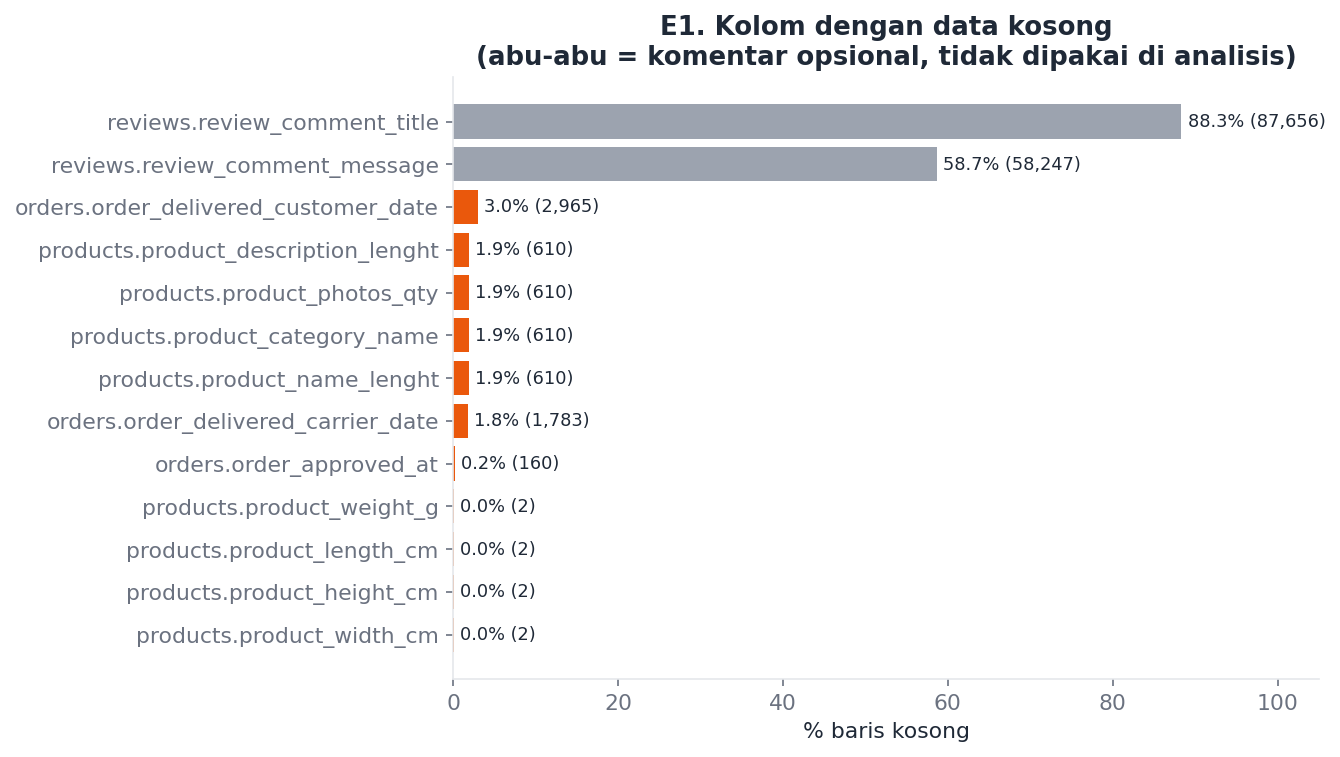


Status order vs tanggal terima kosong:
 tanggal_terima_kosong  False  True 
status                             
approved                   0      2
canceled                   6    619
created                    0      5
delivered              96470      8
invoiced                   0    314
processing                 0    301
shipped                    0   1107
unavailable                0    609


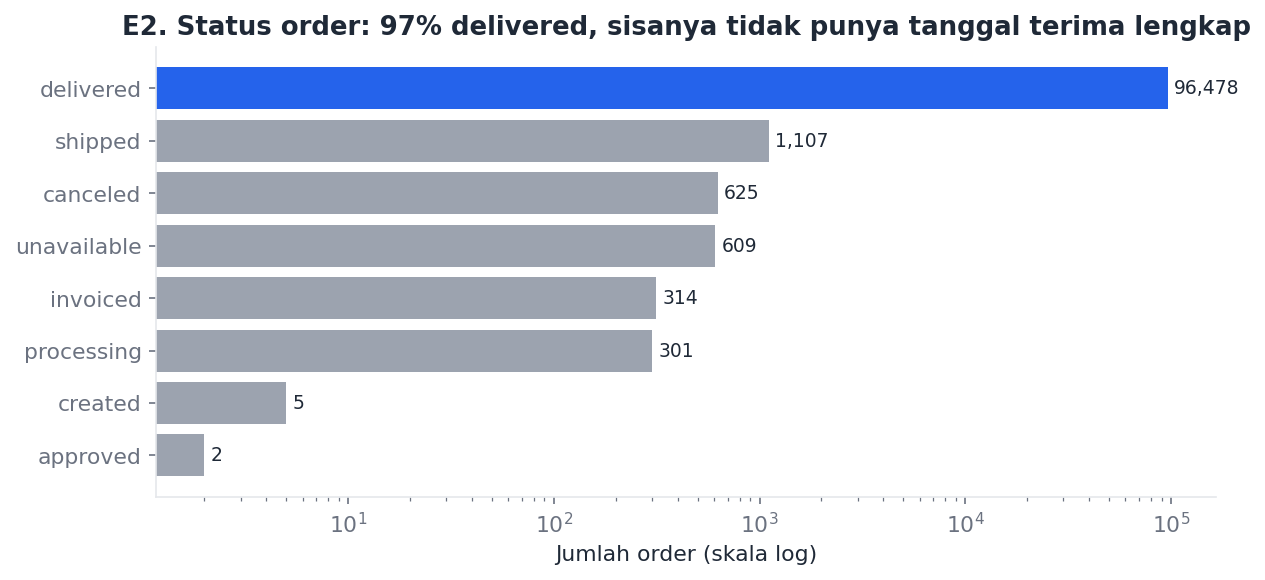


Order dengan >1 review: 547; review_id duplikat: 814


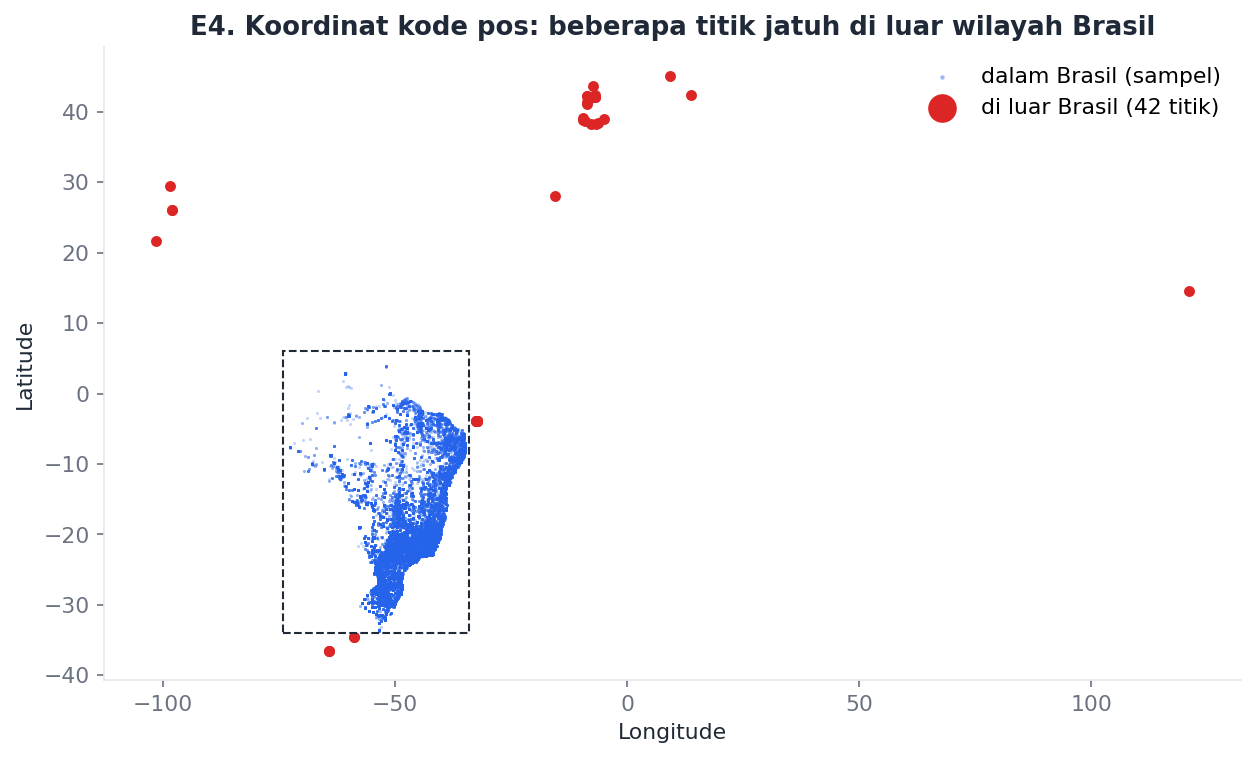


Lama kirim (hari): {'min': 0.53, 'median': 10.22, 'max': 209.63, 'skewness': 3.83, 'batas_atas_IQR': 29.15, 'jumlah_outlier': 4899, 'negatif': 0}


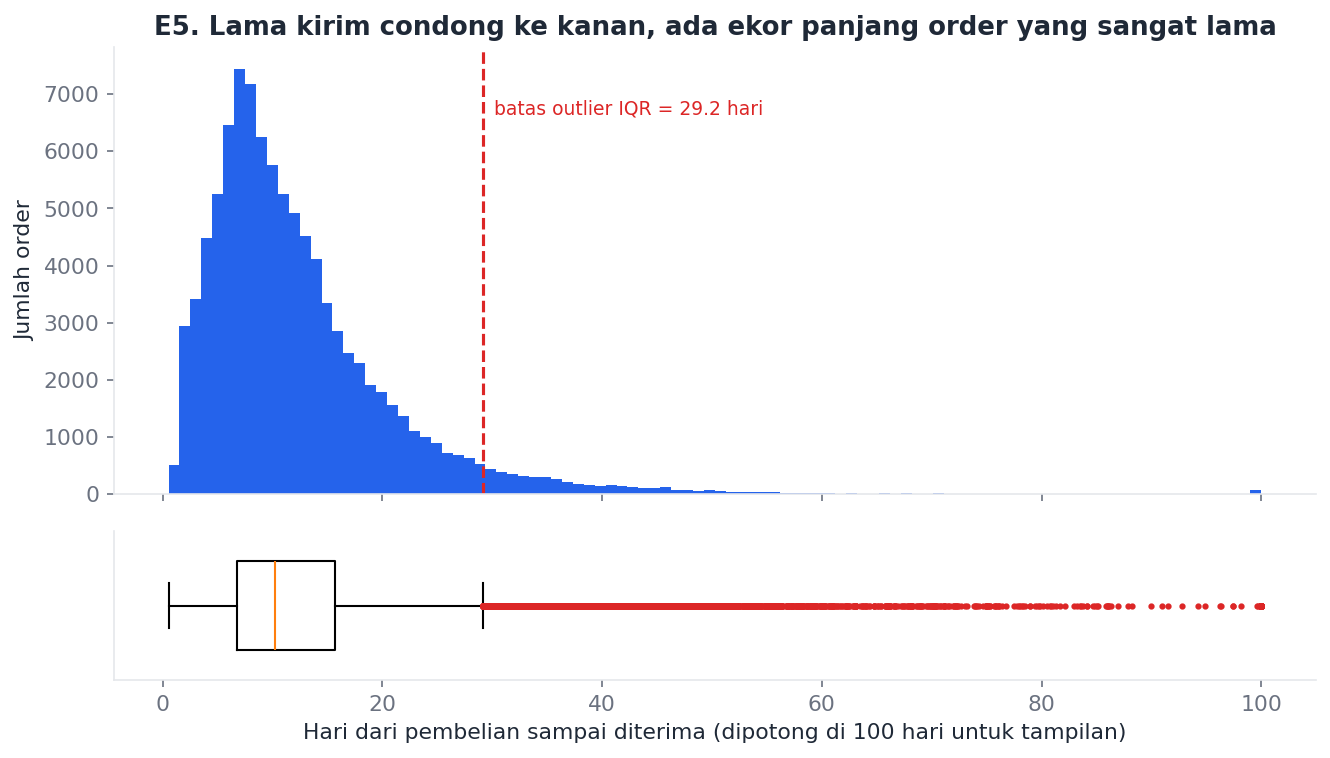

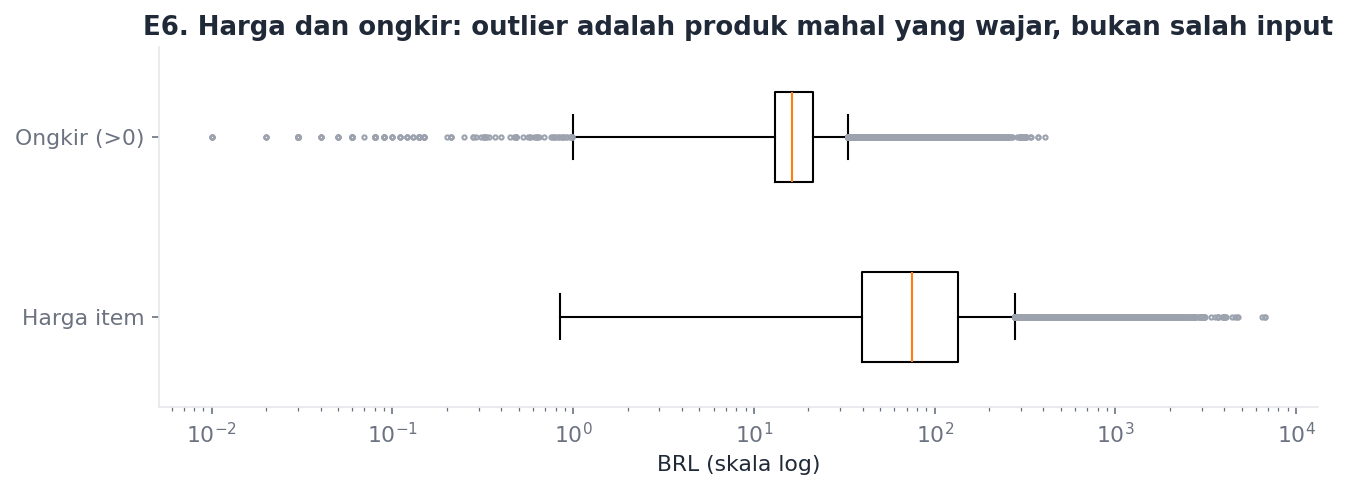

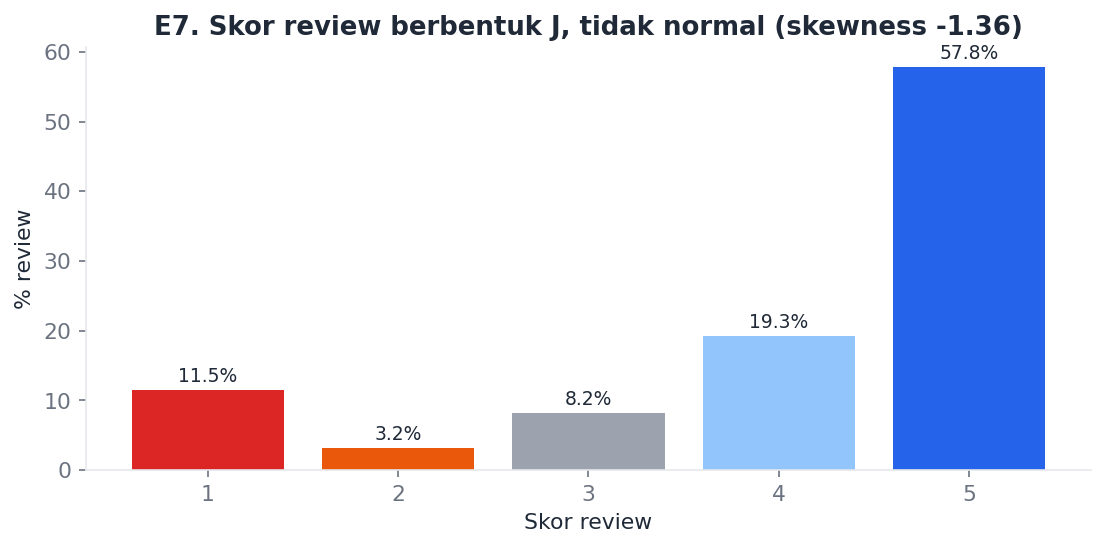

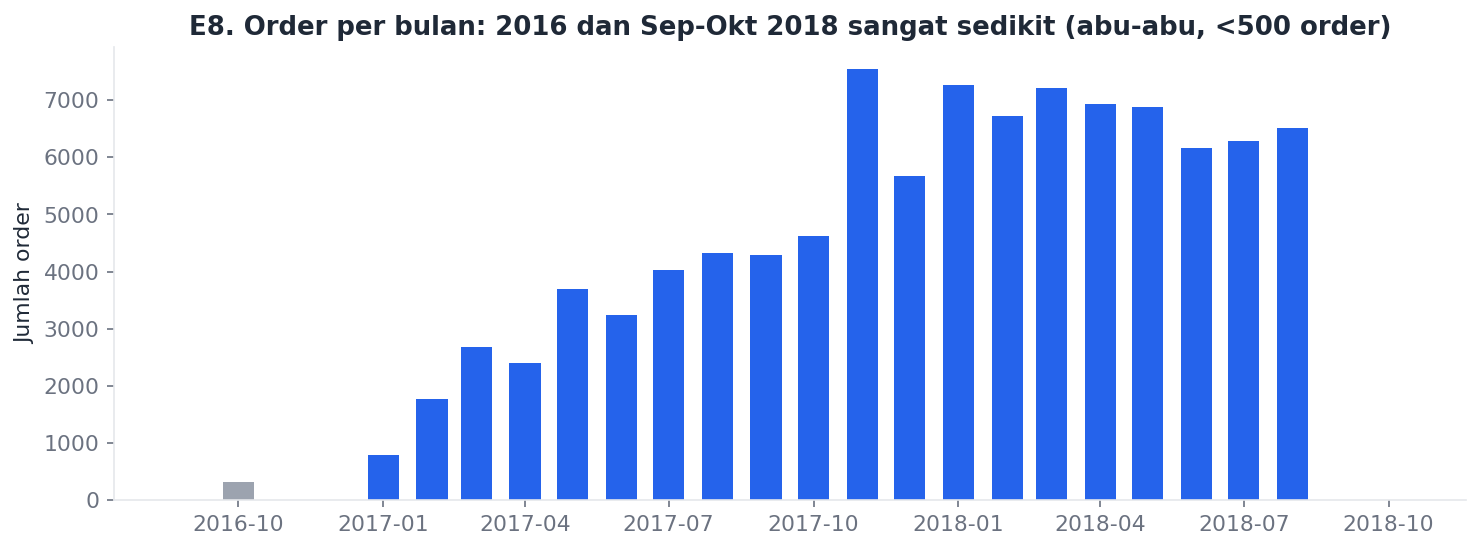

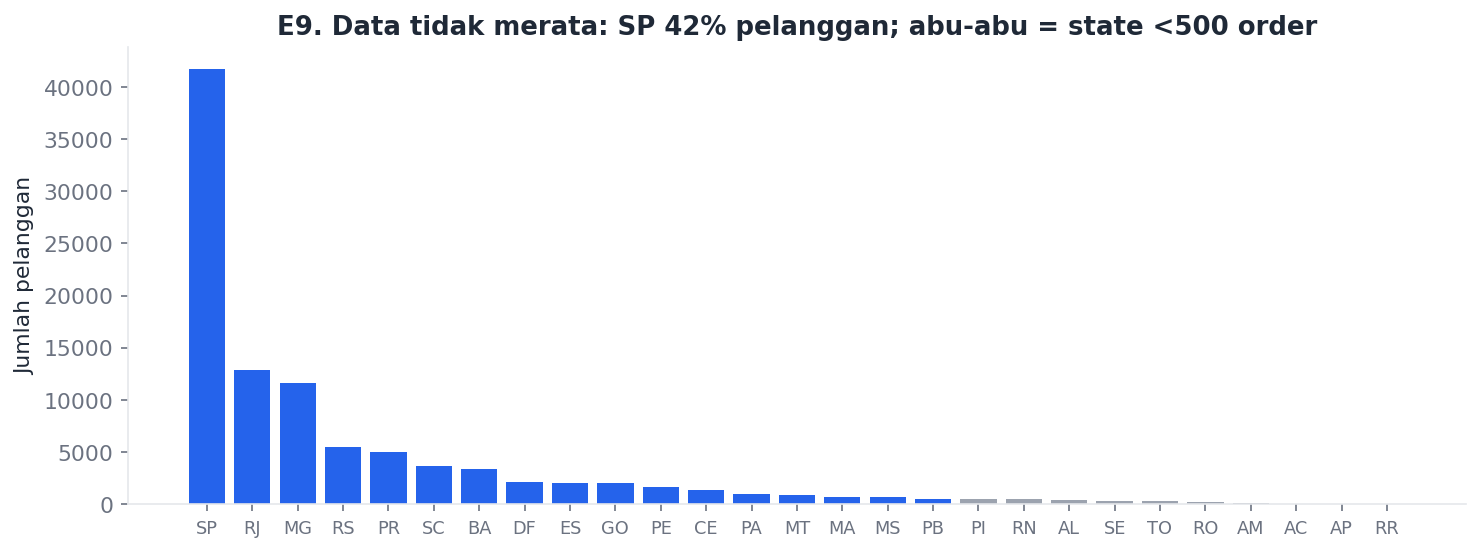

In [6]:
eda = {}
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")

# E1. Missing value per kolom
miss = [{"kolom": f"{n}.{c}", "kosong": int(v), "persen": v / len(d) * 100}
        for n, d in raw.items() for c, v in d.isna().sum().items() if v > 0]
miss = pd.DataFrame(miss).sort_values("persen")
fig, ax = plt.subplots(figsize=(9, 5.2))
b = ax.barh(miss["kolom"], miss["persen"], color=[GRAY if "review_comment" in k else ORANGE for k in miss["kolom"]])
ax.bar_label(b, labels=[f"{p:.1f}% ({k:,})" for p, k in zip(miss["persen"], miss["kosong"])], padding=3, fontsize=8.5, color=INK)
ax.set_xlabel("% baris kosong"); ax.set_xlim(0, 105)
ax.set_title("E1. Kolom dengan data kosong\n(abu-abu = komentar opsional, tidak dipakai di analisis)")
save(fig, "E1_missing_values.png")
eda["missing"] = miss.round(2).to_dict("records")

# E2. Status order dan kaitannya dengan tanggal terima kosong
status = orders["order_status"].value_counts()
cross = pd.crosstab(orders["order_status"], orders["order_delivered_customer_date"].isna(),
                    rownames=["status"], colnames=["tanggal_terima_kosong"])
print("\nStatus order vs tanggal terima kosong:\n", cross)
fig, ax = plt.subplots(figsize=(8.5, 4))
b = ax.barh(status.index[::-1], status.values[::-1], color=[BLUE if s == "delivered" else GRAY for s in status.index[::-1]])
ax.bar_label(b, labels=[f"{v:,}" for v in status.values[::-1]], padding=3, fontsize=9, color=INK)
ax.set_xscale("log"); ax.set_xlabel("Jumlah order (skala log)")
ax.set_title("E2. Status order: 97% delivered, sisanya tidak punya tanggal terima lengkap")
save(fig, "E2_status_order.png")
eda["delivered_tanpa_tanggal"] = int(cross.loc["delivered", True]) if True in cross.columns else 0

# E3. Review ganda per order
rev_per_order = reviews.groupby("order_id").size()
eda["order_review_ganda"] = int((rev_per_order > 1).sum())
eda["review_id_duplikat"] = int(reviews["review_id"].duplicated().sum())
print(f"\nOrder dengan >1 review: {eda['order_review_ganda']:,}; review_id duplikat: {eda['review_id_duplikat']:,}")

# E4. Koordinat geolocation: ada titik di luar Brasil
in_box = geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34)
eda["geo_di_luar_brasil"] = int((~in_box).sum())
smp = geo[in_box].sample(150_000, random_state=42)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(smp["geolocation_lng"], smp["geolocation_lat"], s=0.2, color=BLUE, alpha=.3, rasterized=True, label="dalam Brasil (sampel)")
out = geo[~in_box]
ax.scatter(out["geolocation_lng"], out["geolocation_lat"], s=18, color=RED, label=f"di luar Brasil ({len(out)} titik)")
ax.add_patch(plt.Rectangle((-74, -34), 40, 40, fill=False, ls="--", color=INK, lw=1))
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(frameon=False, loc="upper right", markerscale=3)
ax.set_title("E4. Koordinat kode pos: beberapa titik jatuh di luar wilayah Brasil")
save(fig, "E4_geolocation_outlier.png")

# E5. Distribusi lama kirim (data mentah)
dv = orders.dropna(subset=["order_delivered_customer_date"])
dd = (dv["order_delivered_customer_date"] - dv["order_purchase_timestamp"]).dt.total_seconds() / 86400
q1, q3 = dd.quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
eda["lama_kirim"] = {"min": round(float(dd.min()), 2), "median": round(float(dd.median()), 2), "max": round(float(dd.max()), 2),
                     "skewness": round(float(dd.skew()), 2), "batas_atas_IQR": round(float(fence), 2),
                     "jumlah_outlier": int((dd > fence).sum()), "negatif": int((dd < 0).sum())}
print("\nLama kirim (hari):", eda["lama_kirim"])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.2), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)
a1.hist(dd.clip(upper=100), bins=100, color=BLUE)
a1.axvline(fence, color=RED, ls="--"); a1.text(fence + 1, a1.get_ylim()[1] * .85, f"batas outlier IQR = {fence:.1f} hari", color=RED, fontsize=9)
a1.set_ylabel("Jumlah order"); a1.set_title("E5. Lama kirim condong ke kanan, ada ekor panjang order yang sangat lama")
hbox(a2, dd.clip(upper=100), widths=.6, flierprops={"markersize": 2, "markerfacecolor": RED, "markeredgecolor": RED})
a2.set_yticks([]); a2.set_xlabel("Hari dari pembelian sampai diterima (dipotong di 100 hari untuk tampilan)")
save(fig, "E5_distribusi_lama_kirim.png")

# E6. Harga dan ongkir: outlier wajar atau error?
fig, ax = plt.subplots(figsize=(9, 3.4))
hbox(ax, [items["price"], items["freight_value"].replace(0, np.nan).dropna()], widths=.5,
     flierprops={"markersize": 2, "markeredgecolor": GRAY})
ax.set_yticks([1, 2]); ax.set_yticklabels(["Harga item", "Ongkir (>0)"])
ax.set_xscale("log"); ax.set_xlabel("BRL (skala log)")
ax.set_title("E6. Harga dan ongkir: outlier adalah produk mahal yang wajar, bukan salah input")
save(fig, "E6_harga_ongkir.png")
eda["harga"] = {"min": float(items["price"].min()), "max": float(items["price"].max()),
                "ongkir_nol": int((items["freight_value"] == 0).sum())}

# E7. Distribusi skor review
rs = reviews["review_score"].value_counts(normalize=True).sort_index() * 100
eda["skor_review_persen"] = rs.round(2).to_dict()
eda["skor_review_skewness"] = round(float(reviews["review_score"].skew()), 2)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
b = ax.bar(rs.index.astype(str), rs.values, color=[RED, ORANGE, GRAY, "#93c5fd", BLUE])
ax.bar_label(b, fmt="%.1f%%", padding=2, fontsize=9, color=INK)
ax.set_xlabel("Skor review"); ax.set_ylabel("% review")
ax.set_title(f"E7. Skor review berbentuk J, tidak normal (skewness {eda['skor_review_skewness']})")
save(fig, "E7_distribusi_review.png")

# E8. Volume order per bulan (data mentah)
mon_raw = orders.set_index("order_purchase_timestamp").resample("MS").size()
sparse = mon_raw[mon_raw < 500]
eda["bulan_data_sedikit"] = {k.strftime("%Y-%m"): int(v) for k, v in sparse.items()}
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(mon_raw.index, mon_raw.values, width=20, color=[GRAY if v < 500 else BLUE for v in mon_raw.values])
ax.set_ylabel("Jumlah order"); ax.set_title("E8. Order per bulan: 2016 dan Sep-Okt 2018 sangat sedikit (abu-abu, <500 order)")
save(fig, "E8_order_per_bulan.png")

# E9. Sebaran order per state pelanggan
cs = customers["customer_state"].value_counts()
eda["porsi_state_top3_persen"] = round(float(cs.head(3).sum() / cs.sum() * 100), 2)
fig, ax = plt.subplots(figsize=(10, 3.8))
b = ax.bar(cs.index, cs.values, color=[BLUE if v >= 500 else GRAY for v in cs.values])
ax.set_ylabel("Jumlah pelanggan"); ax.tick_params(axis="x", labelsize=8.5)
ax.set_title(f"E9. Data tidak merata: SP {cs.iloc[0]/cs.sum()*100:.0f}% pelanggan; abu-abu = state <500 order")
save(fig, "E9_sebaran_state.png")

## 4. Data Cleaning
Menerapkan keputusan dari EDA diagnostik. Komentar di tiap blok kode menyebut temuan EDA yang menjadi dasarnya.

In [7]:
log = {}
# 4a. Reviews (temuan E3): satu order bisa punya >1 review -> ambil review terbaru per order
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])
n0 = len(reviews)
reviews = (reviews.sort_values("review_answer_timestamp")
                  .drop_duplicates("order_id", keep="last"))
log["review_duplikat_dihapus"] = n0 - len(reviews)
reviews["has_comment"] = reviews["review_comment_message"].notna()

# 4b. Products (temuan E1): kategori kosong -> 'unknown', terjemahkan, dimensi kosong -> median
log["produk_tanpa_kategori"] = int(products["product_category_name"].isna().sum())
products["product_category_name"] = products["product_category_name"].fillna("unknown")
products = products.merge(cat_tr, on="product_category_name", how="left")
products["category"] = (products["product_category_name_english"]
                        .fillna(products["product_category_name"])
                        .str.replace("_", " ").str.title())
for c in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products[c] = products[c].fillna(products[c].median())

# 4c. Geolocation (temuan profiling + E4): hapus duplikat & titik di luar Brasil, rata-rata per prefix zip
n0 = len(geo)
geo = geo.drop_duplicates()
log["geo_duplikat_dihapus"] = n0 - len(geo)
in_br = geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34)
log["geo_outlier_dihapus"] = int((~in_br).sum())
geo = geo[in_br]
geo_zip = (geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
              .mean().reset_index())
geo_state = (geo.groupby("geolocation_state")[["geolocation_lat", "geolocation_lng"]]
                .mean().reset_index()
                .rename(columns={"geolocation_state": "state", "geolocation_lat": "lat",
                                 "geolocation_lng": "lng"}))

# 4d. Orders (temuan E2 + E5): hanya delivered dengan tanggal terima valid
n0 = len(orders)
delivered = orders[(orders["order_status"] == "delivered") &
                   orders["order_delivered_customer_date"].notna()].copy()
log["order_bukan_delivered_atau_tanpa_tanggal"] = n0 - len(delivered)
bad = delivered["order_delivered_customer_date"] < delivered["order_purchase_timestamp"]
log["order_tanggal_tidak_logis"] = int(bad.sum())
delivered = delivered[~bad]
print(json.dumps(log, indent=2))

{
  "review_duplikat_dihapus": 551,
  "produk_tanpa_kategori": 610,
  "geo_duplikat_dihapus": 261831,
  "geo_outlier_dihapus": 33,
  "order_bukan_delivered_atau_tanpa_tanggal": 2971,
  "order_tanggal_tidak_logis": 0
}


## 5. Validasi Hasil Cleaning
Membandingkan kondisi sebelum dan sesudah cleaning. `assert` memastikan masalah yang ditemukan di EDA sudah bernilai 0; kalau belum, notebook akan berhenti dengan error.

In [8]:
validasi = pd.DataFrame([
    {"cek": "baris orders", "sebelum": len(raw["orders"]), "sesudah": len(delivered)},
    {"cek": "baris reviews", "sebelum": len(raw["reviews"]), "sesudah": len(reviews)},
    {"cek": "order dengan >1 review", "sebelum": eda["order_review_ganda"], "sesudah": int(reviews["order_id"].duplicated().sum())},
    {"cek": "produk tanpa kategori", "sebelum": log["produk_tanpa_kategori"], "sesudah": int(products["product_category_name"].isna().sum())},
    {"cek": "baris geolocation", "sebelum": len(raw["geolocation"]), "sesudah": len(geo)},
    {"cek": "titik di luar Brasil", "sebelum": eda["geo_di_luar_brasil"], "sesudah": int((~(geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34))).sum())},
    {"cek": "order delivered tanpa tanggal terima", "sebelum": eda["delivered_tanpa_tanggal"], "sesudah": int(delivered["order_delivered_customer_date"].isna().sum())},
])
assert validasi.loc[validasi["cek"].isin(["order dengan >1 review", "produk tanpa kategori", "titik di luar Brasil",
                                          "order delivered tanpa tanggal terima"]), "sesudah"].eq(0).all()
validasi.to_csv(os.path.join(OUT, "02_validasi_cleaning.csv"), index=False)
print(validasi.to_string(index=False))

                                 cek  sebelum  sesudah
                        baris orders    99441    96470
                       baris reviews    99224    98673
              order dengan >1 review      547        0
               produk tanpa kategori      610        0
                   baris geolocation  1000163   738299
                titik di luar Brasil       42        0
order delivered tanpa tanggal terima        8        0


## 6. Feature Engineering dan Integrasi Tabel
Variabel baru:
- `delivery_days` = tanggal terima − tanggal beli
- `delay_days` = tanggal terima − tanggal estimasi (positif = telat)
- `is_late` = `delay_days > 0`
- `delay_bucket` = kelompok keterlambatan

Tabel item dan pembayaran diagregasi per order, lalu semua tabel di-*join* (`order_id`, `customer_id`, `product_id`, `seller_id`) menjadi satu tabel fakta `fact`, satu baris per order.

In [9]:
d = delivered
d["delivery_days"] = (d["order_delivered_customer_date"] - d["order_purchase_timestamp"]).dt.total_seconds() / 86400
d["estimated_days"] = (d["order_estimated_delivery_date"] - d["order_purchase_timestamp"]).dt.total_seconds() / 86400
# selisih tanggal (positif = terlambat dari estimasi)
d["delay_days"] = (d["order_delivered_customer_date"].dt.normalize() - d["order_estimated_delivery_date"].dt.normalize()).dt.days
d["is_late"] = d["delay_days"] > 0
d["delay_bucket"] = pd.cut(d["delay_days"], bins=[-1000, -8, 0, 3, 7, 14, 1000],
                           labels=["1. Lebih cepat >7 hari", "2. Tepat waktu / cepat <=7 hari",
                                   "3. Telat 1-3 hari", "4. Telat 4-7 hari", "5. Telat 8-14 hari", "6. Telat >14 hari"])
# nomor di depan label supaya urutannya benar saat diurutkan abjad (misalnya di Tableau)
d["purchase_month"] = d["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

# Agregasi item per order
items = items.merge(products[["product_id", "category"]], on="product_id", how="left")
items = items.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
item_agg = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    price_total=("price", "sum"),
    freight_total=("freight_value", "sum"),
    n_sellers=("seller_id", "nunique"),
    main_category=("category", lambda s: s.mode().iat[0] if not s.mode().empty else "Unknown"),
    seller_state=("seller_state", "first"),
).reset_index()

pay_agg = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_type=("payment_type", lambda s: s.value_counts().index[0]),
    installments=("payment_installments", "max"),
).reset_index()

fact = (d.merge(customers, on="customer_id", how="left")
         .merge(item_agg, on="order_id", how="inner")
         .merge(pay_agg, on="order_id", how="left")
         .merge(reviews[["order_id", "review_score", "has_comment"]], on="order_id", how="left"))
log["order_tanpa_review"] = int(fact["review_score"].isna().sum())
fact["same_state"] = fact["customer_state"] == fact["seller_state"]
fact["freight_ratio"] = fact["freight_total"] / fact["price_total"]
fact["satisfied"] = fact["review_score"] >= 4
fact = fact.merge(geo_zip.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix",
                                          "geolocation_lat": "customer_lat",
                                          "geolocation_lng": "customer_lng"}),
                  on="customer_zip_code_prefix", how="left")

# Outlier waktu kirim (IQR, temuan E5): ditandai, tidak dibuang
q1, q3 = fact["delivery_days"].quantile([.25, .75])
fact["delivery_outlier"] = fact["delivery_days"] > q3 + 1.5 * (q3 - q1)
log["order_final_dianalisis"] = len(fact)
print(f"Tabel fakta: {fact.shape[0]:,} baris x {fact.shape[1]} kolom")

Tabel fakta: 96,470 baris x 35 kolom


## 7. EDA Lanjutan (setelah cleaning)
Tujuannya **memahami hubungan antarvariabel dan memilih metode uji yang tepat**:
- **E10:** sebagian besar order tiba jauh sebelum estimasi, jadi efek keterlambatan terkumpul di ekor kanan. Ini menjelaskan kenapa korelasi nanti tidak besar.
- **E11:** distribusi review order telat dan tepat waktu sangat berbeda dan tidak normal, sehingga dipakai **Mann-Whitney U**, bukan t-test.
- **E12:** matriks korelasi Spearman menunjukkan variabel yang paling terkait dengan review adalah lama kirim dan selisih estimasi. Jumlah item dan jumlah seller juga berkorelasi negatif lemah, sehingga ikut dianalisis.

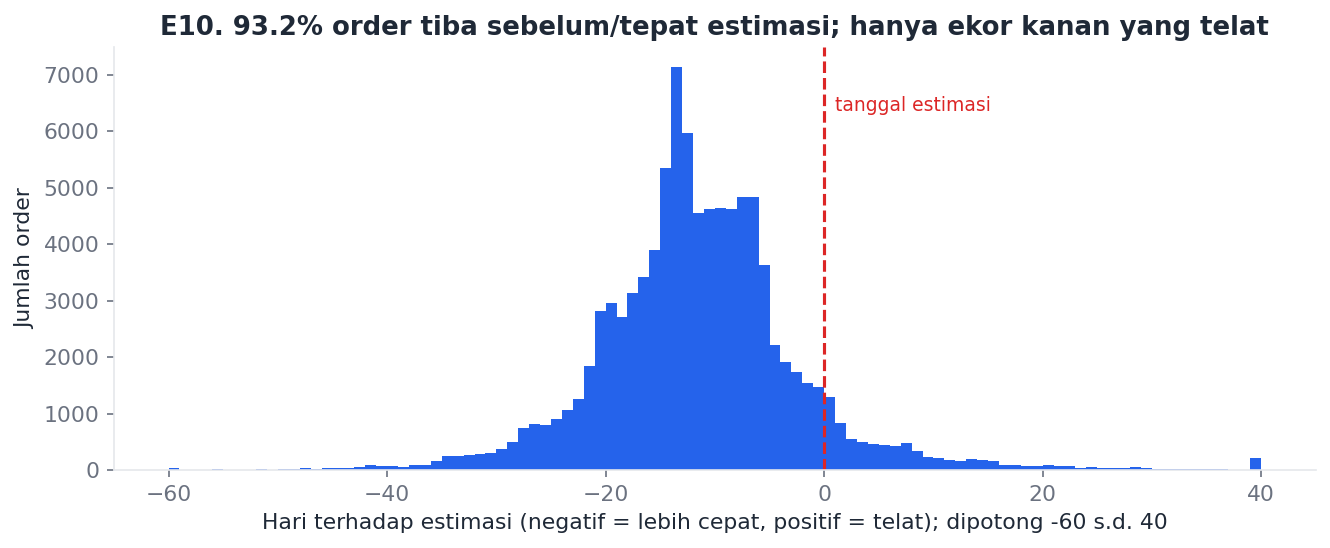

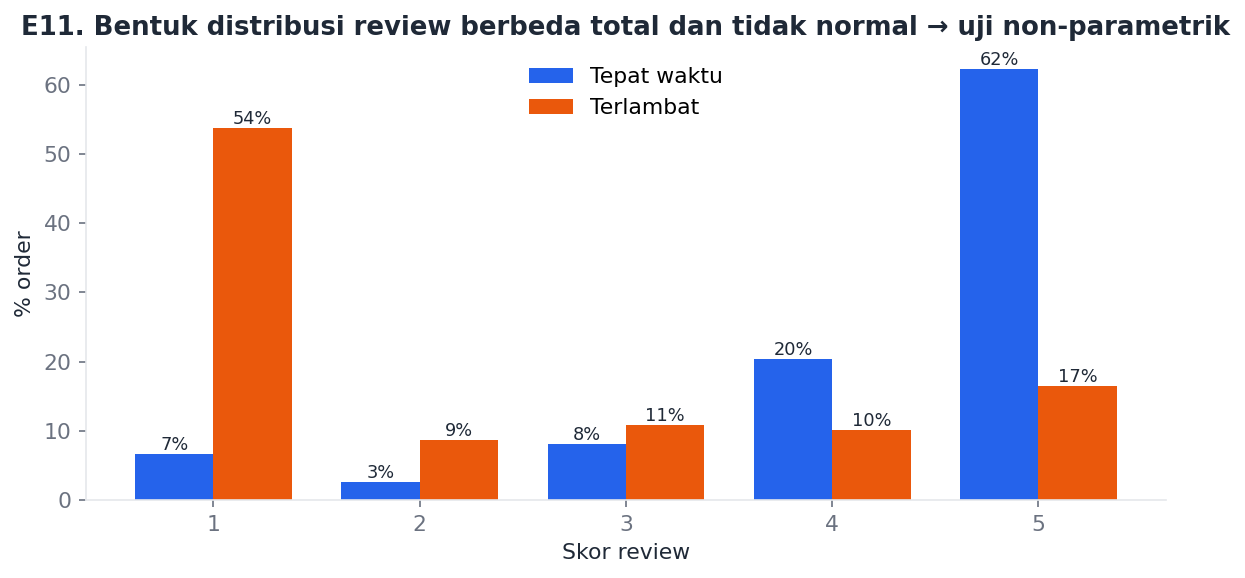

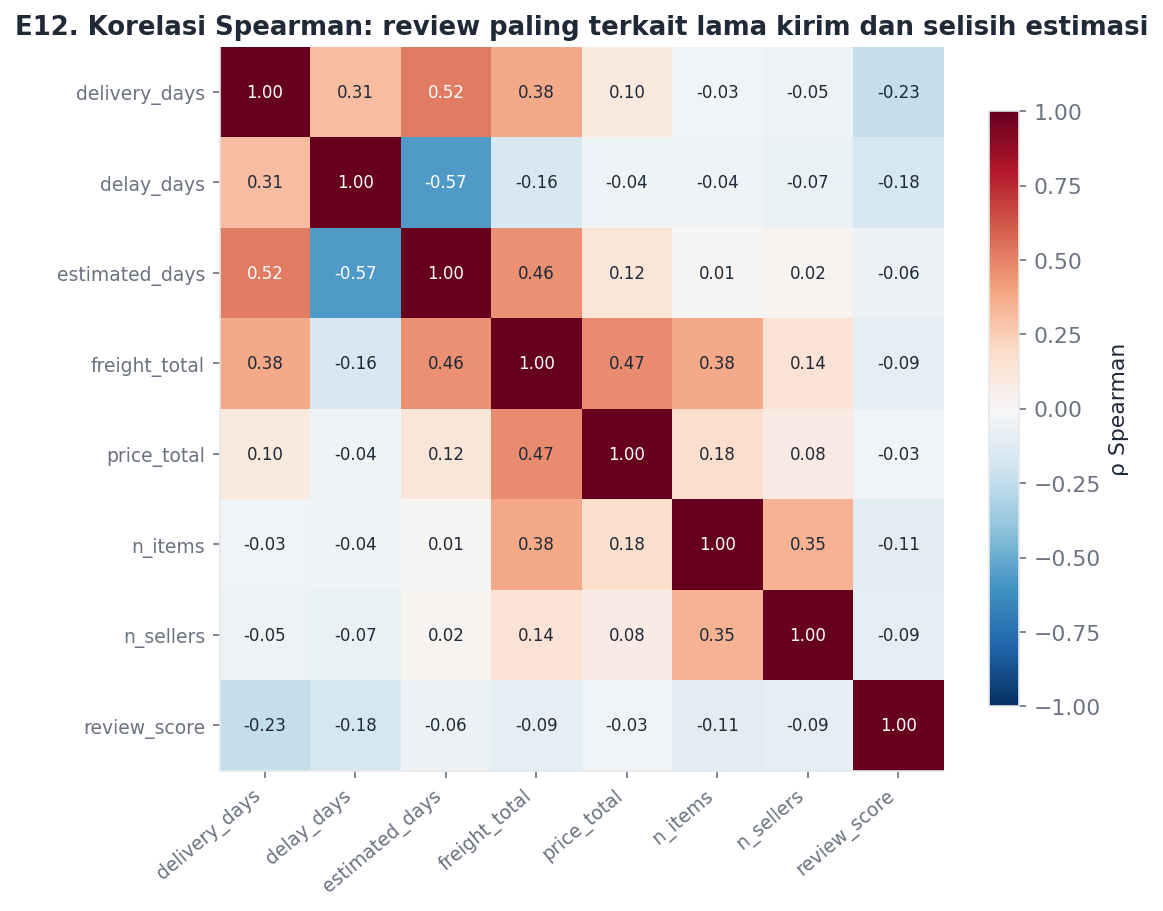

In [10]:
rv = fact.dropna(subset=["review_score"])

# E10. Selisih tanggal terima vs estimasi
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(fact["delay_days"].clip(-60, 40), bins=100, color=BLUE)
ax.axvline(0, color=RED, ls="--"); ax.text(1, ax.get_ylim()[1] * .85, "tanggal estimasi", color=RED, fontsize=9)
ax.set_xlabel("Hari terhadap estimasi (negatif = lebih cepat, positif = telat); dipotong -60 s.d. 40")
ax.set_ylabel("Jumlah order")
ax.set_title(f"E10. {100 - fact['is_late'].mean()*100:.1f}% order tiba sebelum/tepat estimasi; hanya ekor kanan yang telat")
save(fig, "E10_selisih_estimasi.png")

# E11. Distribusi skor review: tepat waktu vs terlambat (dasar pemilihan uji)
dist = (rv.groupby("is_late")["review_score"].value_counts(normalize=True).unstack(0) * 100)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, 6); w = .38
b1 = ax.bar(x - w/2, dist[False], w, color=BLUE, label="Tepat waktu")
b2 = ax.bar(x + w/2, dist[True], w, color=ORANGE, label="Terlambat")
ax.bar_label(b1, fmt="%.0f%%", fontsize=8.5, color=INK); ax.bar_label(b2, fmt="%.0f%%", fontsize=8.5, color=INK)
ax.set_xticks(x); ax.set_xlabel("Skor review"); ax.set_ylabel("% order"); ax.legend(frameon=False)
ax.set_title("E11. Bentuk distribusi review berbeda total dan tidak normal → uji non-parametrik")
save(fig, "E11_distribusi_review_telat.png")

# E12. Korelasi Spearman antar variabel numerik
num = rv[["delivery_days", "delay_days", "estimated_days", "freight_total", "price_total",
          "n_items", "n_sellers", "review_score"]]
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha="right", fontsize=9)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > .5 else INK)
fig.colorbar(im, ax=ax, shrink=.8, label="ρ Spearman")
ax.set_title("E12. Korelasi Spearman: review paling terkait lama kirim dan selisih estimasi")
save(fig, "E12_korelasi_spearman.png")
corr.round(3).to_csv(os.path.join(OUT, "03_korelasi_spearman.csv"))

## 8. Analisis dan Uji Statistik
**Hipotesis:**
- H0: distribusi skor review order terlambat sama dengan order tepat waktu
- H1: skor review order terlambat lebih rendah

**Metode:** Mann-Whitney U (satu sisi) dengan effect size *rank-biserial*, serta korelasi Spearman. Lalu analisis per state, tren bulanan, kategori, pembayaran, rute seller, dan bias representasi. Semua hasil disimpan ke `output/hasil_analisis.json`.

In [11]:
res = {"eda": eda}
res["kpi"] = {
    "total_order_delivered": int(len(fact)),
    "total_pelanggan_unik": int(fact["customer_unique_id"].nunique()),
    "total_revenue_brl": round(float(fact["payment_value"].sum()), 2),
    "rata2_nilai_order_brl": round(float(fact["payment_value"].mean()), 2),
    "rata2_review": round(float(rv["review_score"].mean()), 3),
    "persen_puas_skor4_5": round(float(rv["satisfied"].mean() * 100), 2),
    "persen_terlambat": round(float(fact["is_late"].mean() * 100), 2),
    "rata2_hari_kirim": round(float(fact["delivery_days"].mean()), 2),
    "median_hari_kirim": round(float(fact["delivery_days"].median()), 2),
    "rata2_estimasi_hari": round(float(fact["estimated_days"].mean()), 2),
    "periode": f"{fact['order_purchase_timestamp'].min():%Y-%m-%d} s.d. {fact['order_purchase_timestamp'].max():%Y-%m-%d}",
}
repeat = fact.groupby("customer_unique_id")["order_id"].count()
res["kpi"]["persen_pelanggan_repeat"] = round(float((repeat > 1).mean() * 100), 2)

# Telat vs tepat waktu
lv = rv.groupby("is_late").agg(order=("order_id", "count"), rata2_review=("review_score", "mean"),
                               persen_puas=("satisfied", "mean"),
                               persen_skor1=("review_score", lambda s: (s == 1).mean())).reset_index()
lv["status"] = lv["is_late"].map({True: "Terlambat", False: "Tepat waktu"})
lv[["persen_puas", "persen_skor1"]] *= 100
res["telat_vs_tepat"] = lv.drop(columns="is_late").round(3).to_dict("records")

# Uji hipotesis
# H0: distribusi skor review order terlambat = order tepat waktu
# H1: skor review order terlambat lebih rendah
late_s = rv.loc[rv["is_late"], "review_score"]; ont_s = rv.loc[~rv["is_late"], "review_score"]
u = stats.mannwhitneyu(late_s, ont_s, alternative="less")
effect_r = 1 - 2 * u.statistic / (len(late_s) * len(ont_s))   # rank-biserial correlation
rho = stats.spearmanr(rv["delivery_days"], rv["review_score"])
rho2 = stats.spearmanr(rv["delay_days"], rv["review_score"])
res["uji_statistik"] = {
    "mann_whitney_U": float(u.statistic), "p_value": float(u.pvalue),
    "effect_size_rank_biserial": round(float(effect_r), 3),
    "spearman_hari_kirim_vs_review": round(float(rho.statistic), 4), "p_spearman_hari_kirim": float(rho.pvalue),
    "spearman_selisih_estimasi_vs_review": round(float(rho2.statistic), 4), "p_spearman_selisih": float(rho2.pvalue),
}

bucket = rv.groupby("delay_bucket", observed=True).agg(order=("order_id", "count"),
          rata2_review=("review_score", "mean"), persen_puas=("satisfied", "mean")).reset_index()
bucket["persen_puas"] *= 100
bucket.round(3).to_csv(os.path.join(OUT, "04_review_per_keterlambatan.csv"), index=False)

# Per state pelanggan
st = fact.groupby("customer_state").agg(order=("order_id", "count"),
        revenue=("payment_value", "sum"), rata2_hari_kirim=("delivery_days", "mean"),
        persen_terlambat=("is_late", "mean"), rata2_review=("review_score", "mean"),
        rata2_ongkir=("freight_total", "mean")).reset_index()
st["persen_terlambat"] *= 100
st["porsi_order_persen"] = st["order"] / st["order"].sum() * 100
st = st.merge(geo_state, left_on="customer_state", right_on="state", how="left").drop(columns="state")
st = st.sort_values("order", ascending=False).round(3)
st.to_csv(os.path.join(OUT, "05_per_state.csv"), index=False)

# Tren bulanan (bulan dengan data lengkap, temuan E8: 2017-01 s.d. 2018-08)
mon = fact.groupby("purchase_month").agg(order=("order_id", "count"), revenue=("payment_value", "sum"),
        persen_terlambat=("is_late", "mean"), rata2_review=("review_score", "mean"),
        rata2_hari_kirim=("delivery_days", "mean")).reset_index()
mon["persen_terlambat"] *= 100
mon_full = mon[(mon["purchase_month"] >= "2017-01-01") & (mon["purchase_month"] <= "2018-08-01")].copy()
mon_full[mon_full.columns[1:]] = mon_full[mon_full.columns[1:]].round(3)
mon_full.to_csv(os.path.join(OUT, "06_tren_bulanan.csv"), index=False)

# Kategori
cat = fact.groupby("main_category").agg(order=("order_id", "count"), revenue=("payment_value", "sum"),
        rata2_review=("review_score", "mean"), persen_terlambat=("is_late", "mean"),
        rata2_hari_kirim=("delivery_days", "mean")).reset_index()
cat["persen_terlambat"] *= 100
cat = cat.sort_values("revenue", ascending=False).round(3)
cat.to_csv(os.path.join(OUT, "07_per_kategori.csv"), index=False)
cat_big = cat[cat["order"] >= 500]

# Pembayaran
pay = fact.groupby("payment_type").agg(order=("order_id", "count"), revenue=("payment_value", "sum"),
        rata2_cicilan=("installments", "mean")).reset_index()
pay["porsi_persen"] = pay["order"] / pay["order"].sum() * 100
pay = pay.sort_values("order", ascending=False).round(3)
pay.to_csv(os.path.join(OUT, "08_pembayaran.csv"), index=False)

# Seller satu state vs beda state
ss = fact.groupby("same_state").agg(order=("order_id", "count"), rata2_hari_kirim=("delivery_days", "mean"),
        persen_terlambat=("is_late", "mean"), rata2_review=("review_score", "mean"),
        rata2_ongkir=("freight_total", "mean")).reset_index()
ss["persen_terlambat"] *= 100
ss["rute"] = ss["same_state"].map({True: "Seller & pelanggan satu state", False: "Beda state"})
res["rute_seller"] = ss.drop(columns="same_state").round(3).to_dict("records")

# Multi seller per order
ms = rv.groupby(rv["n_sellers"] > 1).agg(order=("order_id", "count"),
        rata2_review=("review_score", "mean")).reset_index()
res["multi_seller"] = ms.round(3).to_dict("records")

# Bias representasi (temuan E9)
res["bias_representasi"] = {
    "porsi_SP_persen": round(float((fact["customer_state"] == "SP").mean() * 100), 2),
    "porsi_3_state_teratas_persen": round(float(fact["customer_state"].value_counts(normalize=True).head(3).sum() * 100), 2),
    "state_order_kurang_dari_500": st.loc[st["order"] < 500, "customer_state"].tolist(),
    "persen_order_tanpa_review": round(log["order_tanpa_review"] / len(fact) * 100, 2),
    "persen_review_berkomentar": round(float(rv["has_comment"].mean() * 100), 2),
}
res["cleaning_log"] = log
res["top5_state_telat"] = st[st["order"] >= 500].nlargest(5, "persen_terlambat")[
    ["customer_state", "order", "persen_terlambat", "rata2_hari_kirim", "rata2_review"]].to_dict("records")
res["top5_kategori_revenue"] = cat.head(5)[["main_category", "order", "revenue", "rata2_review"]].to_dict("records")
res["kategori_review_terendah"] = cat_big.nsmallest(5, "rata2_review")[
    ["main_category", "order", "rata2_review", "persen_terlambat"]].to_dict("records")

with open(os.path.join(OUT, "hasil_analisis.json"), "w") as f:
    json.dump(res, f, indent=2, default=str, ensure_ascii=False)
print(json.dumps(res["kpi"], indent=2))
print(json.dumps(res["uji_statistik"], indent=2))
print(bucket.round(3).to_string(index=False))

{
  "total_order_delivered": 96470,
  "total_pelanggan_unik": 93350,
  "total_revenue_brl": 15421082.85,
  "rata2_nilai_order_brl": 159.86,
  "rata2_review": 4.156,
  "persen_puas_skor4_5": 78.93,
  "persen_terlambat": 6.77,
  "rata2_hari_kirim": 12.56,
  "median_hari_kirim": 10.22,
  "rata2_estimasi_hari": 23.74,
  "periode": "2016-09-15 s.d. 2018-08-29",
  "persen_pelanggan_repeat": 3.0
}
{
  "mann_whitney_U": 103305546.0,
  "p_value": 0.0,
  "effect_size_rank_biserial": 0.638,
  "spearman_hari_kirim_vs_review": -0.2346,
  "p_spearman_hari_kirim": 0.0,
  "spearman_selisih_estimasi_vs_review": -0.1764,
  "p_spearman_selisih": 0.0
}
                   delay_bucket  order  rata2_review  persen_puas
         1. Lebih cepat >7 hari  70929         4.317       83.493
2. Tepat waktu / cepat <=7 hari  18514         4.189       79.459
              3. Telat 1-3 hari   1852         3.291       53.186
              4. Telat 4-7 hari   1748         2.103       22.483
             5. Telat 8-14 ha

## 9. Export Data Bersih ke Tableau
Python berhenti di sini. Tabel fakta yang bersih diekspor ke `output/tableau/` dan menjadi sumber data **visualisasi akhir di Tableau**. Kolom `late_flag` dan `satisfied_flag` (0/1) dibuat supaya persentase cukup dihitung dengan `AVG()` di Tableau.

In [12]:
tab_cols = ["order_id", "customer_unique_id", "order_purchase_timestamp", "purchase_month",
            "order_delivered_customer_date", "order_estimated_delivery_date",
            "customer_city", "customer_state", "customer_lat", "customer_lng", "seller_state", "same_state",
            "main_category", "n_items", "n_sellers", "price_total", "freight_total", "payment_value",
            "payment_type", "installments", "delivery_days", "estimated_days", "delay_days", "is_late",
            "delay_bucket", "delivery_outlier", "review_score", "satisfied"]
tab = fact[tab_cols].copy()
tab["late_flag"] = tab["is_late"].astype(int)          # 1 = terlambat, untuk AVG() di Tableau
tab["satisfied_flag"] = tab["satisfied"].astype(int)   # 1 = review 4-5
tab["purchase_month"] = tab["purchase_month"].dt.strftime("%Y-%m-%d")
num_cols = tab.select_dtypes("number").columns
tab[num_cols] = tab[num_cols].round(4)
tab.to_csv(os.path.join(TAB, "olist_orders_clean.csv"), index=False)
st.to_csv(os.path.join(TAB, "olist_state_summary.csv"), index=False)
mon_full.assign(purchase_month=mon_full["purchase_month"].dt.strftime("%Y-%m-%d")).to_csv(
    os.path.join(TAB, "olist_monthly_trend.csv"), index=False)
cat.to_csv(os.path.join(TAB, "olist_category_summary.csv"), index=False)
print("Export selesai:", sorted(os.listdir(TAB)))

Export selesai: ['olist_category_summary.csv', 'olist_monthly_trend.csv', 'olist_orders_clean.csv', 'olist_state_summary.csv']


## 10. Kesimpulan
- H0 ditolak: review order terlambat (rata-rata **2,27**) jauh lebih rendah dari order tepat waktu (**4,29**); Mann-Whitney U p < 0,001, effect size rank-biserial 0,64 (besar).
- Korelasi Spearman lama kirim vs review: ρ = −0,235, karena efeknya terkumpul di 6,8% order yang telat (E10).
- Keterlambatan melonjak saat puncak permintaan (Nov 2017, Feb-Mar 2018).
- State MA, CE, BA, PA, dan RJ punya keterlambatan di atas rata-rata 6,8%.
- Order dengan seller satu state lebih cepat (7,9 vs 15,2 hari) dan lebih jarang terlambat.

Visualisasi hasil akhir disajikan di dashboard Tableau.